In [5]:
# Week 4: Predictive Model Building
# Project: Paneer Storage Study

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Locate the dataset relative to this notebook
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "paneer_feature_engineered.csv"

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("=" * 50)
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (70, 33)

Column names:
['Day', 'Replicate', 'TPC_CFU_ml', 'TPC_Dilution', 'TPC_Log10', 'Coliform_CFU_ml', 'Coliform_Dilution', 'Coliform_Log10', 'Yeast_Mold_CFU_ml', 'Yeast_Mold_Dilution', 'Yeast_Mold_Log10', 'Psychrophilic_CFU_ml', 'Psychrophilic_Dilution', 'Psychrophilic_Log10', 'Colour_Appearance', 'Body_Texture', 'Flavour', 'Overall_Acceptability', 'pH', 'Moisture_Percent', 'Milk_Quantity', 'Paneer_Quantity', 'Yield_Percent', 'Fat_Percent', 'Storage_Phase', 'Baseline_TPC_Log10', 'Baseline_pH', 'Baseline_Moisture_Percent', 'TPC_Log_Change', 'pH_Change_From_Baseline', 'Moisture_Change_From_Baseline', 'Baseline_TPC_Count', 'TPC_Growth_Ratio']

First five rows:


,Day,Replicate,TPC_CFU_ml,TPC_Dilution,TPC_Log10,Coliform_CFU_ml,Coliform_Dilution,Coliform_Log10,Yeast_Mold_CFU_ml,Yeast_Mold_Dilution,...,Fat_Percent,Storage_Phase,Baseline_TPC_Log10,Baseline_pH,Baseline_Moisture_Percent,TPC_Log_Change,pH_Change_From_Baseline,Moisture_Change_From_Baseline,Baseline_TPC_Count,TPC_Growth_Ratio
0,0,1,20,1,2.301030,0,0,NaN,0,0,...,23.456,Early,2.301030,5.70,53.28,0.0,0.0,0.0,20,1.0
1,0,2,12,1,2.079181,0,0,NaN,0,0,...,25.469,Early,2.079181,5.98,52.55,0.0,0.0,0.0,12,1.0
2,0,3,17,1,2.230449,0,0,NaN,0,0,...,24.631,Early,2.230449,5.84,53.47,0.0,0.0,0.0,17,1.0
3,0,4,29,1,2.462398,0,0,NaN,0,0,...,23.432,Early,2.462398,5.90,53.06,0.0,0.0,0.0,29,1.0
4,0,5,24,1,2.380211,0,0,NaN,0,0,...,23.459,Early,2.380211,5.84,52.37,0.0,0.0,0.0,24,1.0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 33 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Day                            70 non-null     int64  
 1   Replicate                      70 non-null     int64  
 2   TPC_CFU_ml                     70 non-null     int64  
 3   TPC_Dilution                   70 non-null     int64  
 4   TPC_Log10                      70 non-null     float64
 5   Coliform_CFU_ml                70 non-null     int64  
 6   Coliform_Dilution              70 non-null     int64  
 7   Coliform_Log10                 46 non-null     float64
 8   Yeast_Mold_CFU_ml              70 non-null     int64  
 9   Yeast_Mold_Dilution            70 non-null     int64  
 10  Yeast_Mold_Log10               56 non-null     float64
 11  Psychrophilic_CFU_ml           70 non-null     int64  
 12  Psychrophilic_Dilution         70 non-nul

Day                               0
Replicate                         0
TPC_CFU_ml                        0
TPC_Dilution                      0
TPC_Log10                         0
Coliform_CFU_ml                   0
Coliform_Dilution                 0
Coliform_Log10                   24
Yeast_Mold_CFU_ml                 0
Yeast_Mold_Dilution               0
Yeast_Mold_Log10                 14
Psychrophilic_CFU_ml              0
Psychrophilic_Dilution            0
Psychrophilic_Log10               9
Colour_Appearance                20
Body_Texture                     20
Flavour                          20
Overall_Acceptability            20
pH                                0
Moisture_Percent                  0
Milk_Quantity                    65
Paneer_Quantity                  65
Yield_Percent                    65
Fat_Percent                      65
Storage_Phase                     0
Baseline_TPC_Log10                0
Baseline_pH                       0
Baseline_Moisture_Percent   

In [6]:
# Step 5: Define target and input features

TARGET = "TPC_Log10"

FEATURES = [
    "Day",
    "pH",
    "Moisture_Percent",
    "Replicate",
]

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Target variable:", TARGET)
print("Input features:", FEATURES)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in input features:")
print(X.isna().sum())

print("\nTarget missing values:", y.isna().sum())

print("\nPreview of model inputs:")
display(X.head())

print("\nPreview of target:")
display(y.head())

Target variable: TPC_Log10
Input features: ['Day', 'pH', 'Moisture_Percent', 'Replicate']
Feature matrix shape: (70, 4)
Target shape: (70,)

Missing values in input features:
Day                 0
pH                  0
Moisture_Percent    0
Replicate           0
dtype: int64

Target missing values: 0

Preview of model inputs:


,Day,pH,Moisture_Percent,Replicate
0,0,5.70,53.28,1
1,0,5.98,52.55,2
2,0,5.84,53.47,3
3,0,5.90,53.06,4
4,0,5.84,52.37,5



Preview of target:


0    2.301030
1    2.079181
2    2.230449
3    2.462398
4    2.380211
Name: TPC_Log10, dtype: float64

In [7]:
# Step 6: Day-based train-test split and baseline model

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Hold out the last 3 storage days for testing
train_mask = df["Day"] <= 10
test_mask = df["Day"] > 10

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training days:", sorted(df.loc[train_mask, "Day"].unique()))
print("Testing days:", sorted(df.loc[test_mask, "Day"].unique()))

# Train baseline linear regression model
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)

# Predict on unseen storage days
y_pred = baseline_model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nBASELINE MODEL RESULTS")
print("=" * 40)
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# Compare actual and predicted values
results = pd.DataFrame({
    "Day": df.loc[test_mask, "Day"].values,
    "Actual_TPC_Log10": y_test.values,
    "Predicted_TPC_Log10": y_pred
})

display(results)


Training observations: 55
Testing observations: 15
Training days: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Testing days: [np.int64(11), np.int64(12), np.int64(13)]

BASELINE MODEL RESULTS
MAE:  0.1180
RMSE: 0.1524
R²:   0.2208


,Day,Actual_TPC_Log10,Predicted_TPC_Log10
0,11,5.176091,5.313545
1,11,5.568202,5.345822
2,11,5.431364,5.315908
3,11,5.414973,5.368400
4,11,5.414973,5.410452
5,12,5.568202,5.576255
6,12,5.477121,5.599199
7,12,5.672098,5.634789
8,12,5.602060,5.661489
9,12,5.755875,5.661786


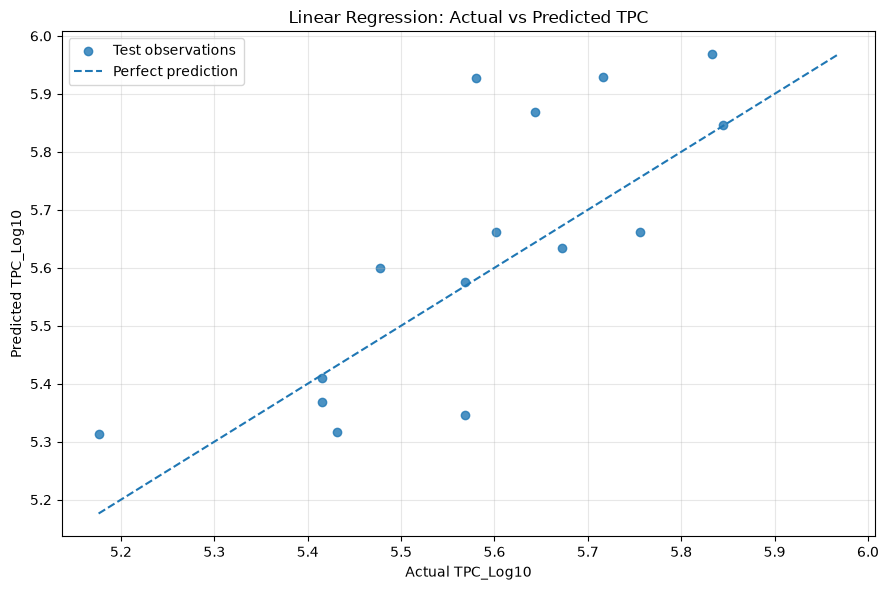

In [8]:
# Step 7: Actual vs Predicted TPC_Log10

plt.figure(figsize=(9, 6))

plt.scatter(
    results["Actual_TPC_Log10"],
    results["Predicted_TPC_Log10"],
    alpha=0.8,
    label="Test observations"
)

# Reference line: perfect predictions
min_value = min(
    results["Actual_TPC_Log10"].min(),
    results["Predicted_TPC_Log10"].min()
)

max_value = max(
    results["Actual_TPC_Log10"].max(),
    results["Predicted_TPC_Log10"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual TPC_Log10")
plt.ylabel("Predicted TPC_Log10")
plt.title("Linear Regression: Actual vs Predicted TPC")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

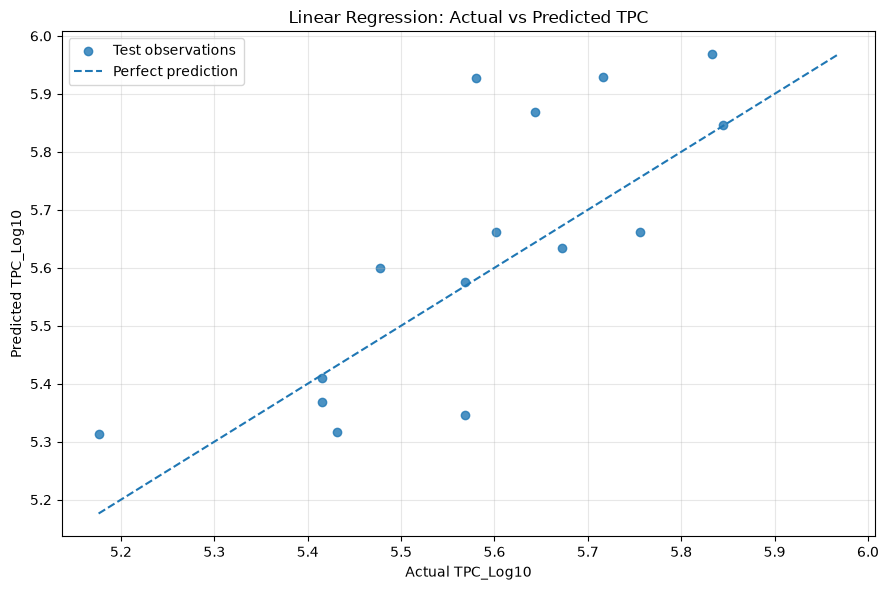

Graph saved to: c:\Users\drish\Desktop\DOC\yuva intern\week 4 predictive modeling\visualizations\actual_vs_predicted_linear_regression.png


In [9]:
from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "visualizations"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 6))

plt.scatter(
    results["Actual_TPC_Log10"],
    results["Predicted_TPC_Log10"],
    alpha=0.8,
    label="Test observations"
)

min_value = min(
    results["Actual_TPC_Log10"].min(),
    results["Predicted_TPC_Log10"].min()
)
max_value = max(
    results["Actual_TPC_Log10"].max(),
    results["Predicted_TPC_Log10"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual TPC_Log10")
plt.ylabel("Predicted TPC_Log10")
plt.title("Linear Regression: Actual vs Predicted TPC")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "actual_vs_predicted_linear_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved to:", OUTPUT_DIR / "actual_vs_predicted_linear_regression.png")

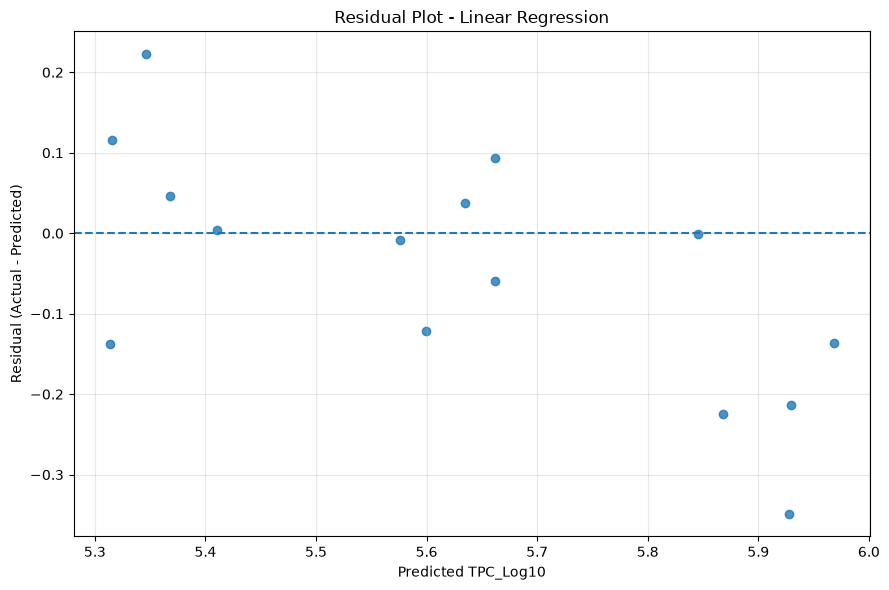

Residual plot saved successfully!
Mean residual: -0.0486
Maximum absolute residual: 0.3483


In [10]:
# Residual Analysis for Linear Regression

results["Residual"] = (
    results["Actual_TPC_Log10"] - results["Predicted_TPC_Log10"]
)

plt.figure(figsize=(9, 6))

plt.scatter(
    results["Predicted_TPC_Log10"],
    results["Residual"],
    alpha=0.8
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted TPC_Log10")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot - Linear Regression")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "visualizations" / "residual_plot_linear_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Residual plot saved successfully!")
print("Mean residual:", round(results["Residual"].mean(), 4))
print("Maximum absolute residual:", round(results["Residual"].abs().max(), 4))

In [11]:
# Week 4: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Train the model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=2,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predict on the same test set
rf_predictions = rf_model.predict(X_test)

# Evaluate performance
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST REGRESSION RESULTS")
print("=" * 40)
print(f"MAE:  {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²:   {rf_r2:.4f}")

# Save predictions
rf_results = pd.DataFrame({
    "Day": df.loc[test_mask, "Day"].values,
    "Actual_TPC_Log10": y_test.values,
    "Predicted_TPC_Log10": rf_predictions
})

display(rf_results.head(10))

RANDOM FOREST REGRESSION RESULTS
MAE:  0.4679
RMSE: 0.4968
R²:   -7.2812


,Day,Actual_TPC_Log10,Predicted_TPC_Log10
0,11,5.176091,5.117471
1,11,5.568202,5.121868
2,11,5.431364,4.981493
3,11,5.414973,5.119820
4,11,5.414973,5.123181
5,12,5.568202,5.117471
6,12,5.477121,5.121868
7,12,5.672098,5.125275
8,12,5.602060,5.119820
9,12,5.755875,5.123181


In [12]:
# Compare the two regression models

model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2_Score": [r2, rf_r2]
})

display(model_comparison.round(4))

# Save the comparison table
REPORT_DIR = PROJECT_ROOT / "report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

model_comparison.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

print("Model comparison saved to:", REPORT_DIR / "model_comparison.csv")

,Model,MAE,RMSE,R2_Score
0,Linear Regression,0.1180,0.1524,0.2208
1,Random Forest,0.4679,0.4968,-7.2812


Model comparison saved to: c:\Users\drish\Desktop\DOC\yuva intern\week 4 predictive modeling\report\model_comparison.csv


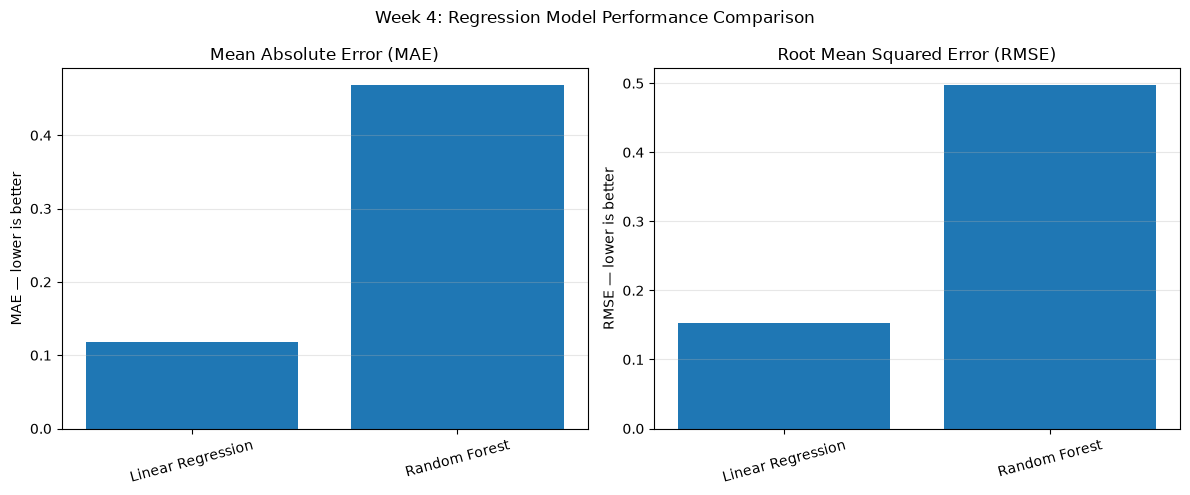

Model comparison chart saved successfully!


In [13]:
# Visual comparison of model performance

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare MAE
axes[0].bar(
    model_comparison["Model"],
    model_comparison["MAE"]
)
axes[0].set_title("Mean Absolute Error (MAE)")
axes[0].set_ylabel("MAE — lower is better")
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(axis="y", alpha=0.3)

# Compare RMSE
axes[1].bar(
    model_comparison["Model"],
    model_comparison["RMSE"]
)
axes[1].set_title("Root Mean Squared Error (RMSE)")
axes[1].set_ylabel("RMSE — lower is better")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Week 4: Regression Model Performance Comparison")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "visualizations" / "model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison chart saved successfully!")

In [14]:
# Save predictions from both models

linear_results = results[
    ["Day", "Actual_TPC_Log10", "Predicted_TPC_Log10"]
].copy()

linear_results["Model"] = "Linear Regression"

random_forest_results = rf_results.copy()
random_forest_results["Model"] = "Random Forest"

all_predictions = pd.concat(
    [linear_results, random_forest_results],
    ignore_index=True
)

# Save predictions to the report folder
predictions_path = REPORT_DIR / "model_predictions.csv"

all_predictions.to_csv(predictions_path, index=False)

print("Predictions saved successfully!")
print("File:", predictions_path)
print("Total prediction records:", len(all_predictions))

display(all_predictions.head(10))

Predictions saved successfully!
File: c:\Users\drish\Desktop\DOC\yuva intern\week 4 predictive modeling\report\model_predictions.csv
Total prediction records: 30


,Day,Actual_TPC_Log10,Predicted_TPC_Log10,Model
0,11,5.176091,5.313545,Linear Regression
1,11,5.568202,5.345822,Linear Regression
2,11,5.431364,5.315908,Linear Regression
3,11,5.414973,5.368400,Linear Regression
4,11,5.414973,5.410452,Linear Regression
5,12,5.568202,5.576255,Linear Regression
6,12,5.477121,5.599199,Linear Regression
7,12,5.672098,5.634789,Linear Regression
8,12,5.602060,5.661489,Linear Regression
9,12,5.755875,5.661786,Linear Regression


In [15]:
# Verify Week 4 output files

expected_files = [
    PROJECT_ROOT / "visualizations" / "actual_vs_predicted_linear_regression.png",
    PROJECT_ROOT / "visualizations" / "residual_plot_linear_regression.png",
    PROJECT_ROOT / "visualizations" / "model_performance_comparison.png",
    PROJECT_ROOT / "report" / "model_comparison.csv",
    PROJECT_ROOT / "report" / "model_predictions.csv",
]

print("WEEK 4 FILE CHECK")
print("=" * 40)

for file_path in expected_files:
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"{status}: {file_path.name}")

print("\nPrediction records:", len(all_predictions))
print("\nModel metrics:")
display(model_comparison.round(4))

WEEK 4 FILE CHECK
FOUND: actual_vs_predicted_linear_regression.png
FOUND: residual_plot_linear_regression.png
FOUND: model_performance_comparison.png
FOUND: model_comparison.csv
FOUND: model_predictions.csv

Prediction records: 30

Model metrics:


,Model,MAE,RMSE,R2_Score
0,Linear Regression,0.1180,0.1524,0.2208
1,Random Forest,0.4679,0.4968,-7.2812
